# Coursework 2 Part 1
**Replace CID in the file name with your CID**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import seaborn as sns

# Importing losses, activation functions and layers from PyTorch
from torch.nn import Sequential, CrossEntropyLoss, Conv1d, MaxPool1d, Flatten, Linear, ReLU, Softmax, Parameter
from torch.nn import Conv2d, MaxPool2d, ConvTranspose2d, MSELoss, Linear
from torch.utils.data import TensorDataset, DataLoader

SMALL_SIZE = 12
MEDIUM_SIZE = 16
BIGGER_SIZE = 20
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# Outline


- [Task 1](#task-1): Dimensionality Reduction and Regression with Convolutional Neural Networks - CNNs
 <a name="index-task-1"></a>
  - [(1.1)](#task-11) <a name="index-task-11"></a>
  - [(1.2)](#task-12) <a name="index-task-12"></a>
- [Task 2](#task-2): Graph-based learning <a name="index-task-2"></a>
  - [(2.1)](#task-21) <a name="index-task-21"></a>
  - [(2.2)](#task-22)  <a name="index-task-22"></a>

<a name="task-1"></a>

# Task 1: Dimensionality Reduction and Regression with Convolutional Neural Networks - CNNs [(index)](#index-task-1)

<a name="task-11"></a>

## (1.1) [(index)](#index-task-11)

In [2]:
from mmap import MAP_ANON
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
PATH='/content/drive/MyDrive/data_science_cw2/'
dataset = pd.read_csv(PATH + "gene_expression_transcriptomic_data.csv")

data_train = dataset.iloc[:1848, :100].values # extract the first 1848 rows and 100 columns
data_val = dataset.iloc[1848:1848+264, :100].values # extract the first 264 rows and 100 columns
data_test = dataset.iloc[1848+264:1848+264+529, :100].values # extract the first 529 rows and 100 columns

MAP7_train = dataset.iloc[:1848, 100].values # extract the corresponding 1848 MAP7 labels
MAP7_val = dataset.iloc[1848:1848+264, 100].values # extract
MAP7_test = dataset.iloc[1848+264:1848+264+529, 100].values

treatment_train = dataset.iloc[:, 101].values[:1848, ] # extract the corresponding 1848 treatment labels
treatment_val = dataset.iloc[:, 101].values[1848:1848+264, ] # extract the corresponding 264 treatment labels
treatment_test = dataset.iloc[:, 101].values[1848+264:1848+264+529] # extract the corresponding 529 treatment labels

classes=[0,1]

X_train = data_train.reshape(data_train.shape[0], 10, 10)
X_val = data_val.reshape(data_val.shape[0], 10, 10)
X_test = data_test.reshape(data_test.shape[0], 10, 10)
X_train = X_train[:, np.newaxis, :, :]
X_val = X_val[:, np.newaxis, :, :]
X_test = X_test[:, np.newaxis, :, :]

Mounted at /content/drive


In [3]:
# Numpy arrays to PyTorch tensors
x_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(treatment_train, dtype=torch.float32)
x_val_tensor = torch.tensor(X_val, dtype=torch.float32)

y_val_tensor = torch.tensor(treatment_val, dtype=torch.float32)
x_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(treatment_test, dtype=torch.float32)

map7_train_tensor = torch.tensor(MAP7_train, dtype=torch.float32)
map7_val_tensor = torch.tensor(MAP7_val, dtype=torch.float32)
map7_test_tensor = torch.tensor(MAP7_test, dtype=torch.float32)


# Creating training and validation datasets
train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

# Creating corresponding DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [4]:
def get_model(x_train, n_filters, k, pool_size, stride_pool):
    """
    CNN model in PyTorch:
    - Layers are Conv1d(+ReLU), MaxPool1d, Flatten and Linear(+Softmax).
    - It features an Adam optimiser and CrossEntropyLoss criterion.

    Parameters:
        x_train (np.ndarray): Training data
        n_filters (int): Number of filters to be used in the convolutional layer
        k (int): Kernel size in the convolutional layer
        pool_size (int): MaxPool1d window size
        stride_pool (int): Stride of the MaxPool1d sliding window
        classes (List): Output classes

    Returns:
        Model, criterion and optimiser.

    """

    model = Sequential(
        Conv2d(in_channels=1, out_channels=n_filters, kernel_size=k, padding=1),
        ReLU(),
        MaxPool2d(kernel_size=pool_size, stride=stride_pool),
        Conv2d(in_channels=n_filters, out_channels=n_filters, kernel_size=k, padding=1),
        ReLU(),
        ConvTranspose2d(in_channels=n_filters, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1),
        ReLU()
    )

    criterion = torch.nn.CrossEntropyLoss() ## <-- SOLUTION
    optimiser = torch.optim.Adam(model.parameters()) ## <-- SOLUTION

    return model, criterion, optimiser


In [5]:
n_filters = 8
k = 3
pool_size = 2
stride_pool = 2

model, criterion, optimiser = get_model(X_train, n_filters, k, pool_size, stride_pool) ## <-- SOLUTION
print(model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): ConvTranspose2d(8, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (6): ReLU()
)


In [6]:
def compute_mse_loss(original, reconstructed):
    batch_size = original.size(0)
    error = (original.flatten(start_dim=1) - reconstructed.flatten(start_dim=1)) ** 2
    total_loss = torch.mean(torch.sum(error, dim=1))
    return total_loss


In [7]:
class EarlyStopping:
    """
    EarlyStopping class.

    Attributes:
        max_patience (int): Amount of epochs with no improvement after which training is stopped.
        patience (int): Stores the number of epochs with no improvement.
        best_valid_loss (float): Stores the current value of the best (minimum) validation loss.
        early_stop (bool) True if training needs to be stopped due to the early stopping condition being met.

    Methods:
        step(val_loss):
            Checks current state after an epoch and updates best_loss, patience and early_stop accordingly.
    """

    def __init__(self, max_patience=5):
        self.max_patience = max_patience
        self.patience = 0
        self.best_valid_loss = float('inf') ## <-- SOLUTION
        self.early_stop = False

    def step(self, val_loss):
        if val_loss < self.best_valid_loss:  ## <-- SOLUTION
            self.best_valid_loss = val_loss  ## <-- SOLUTION
            self.patience = 0  ## <-- SOLUTION
        else:
            self.patience += 1
            if self.patience >= self.max_patience:
                self.early_stop = True

In [8]:
def training_loop(train_loader, val_loader, max_num_epochs=100, max_patience=5):
    """
    Training loop with early stopping to monitor the validation accuracy.

    Parameters:
        train_loader (torch.utils.data.DataLoader): Training DataLoader
        val_loader (torch.utils.data.DataLoader): Validation DataLoader
        max_num_epochs (int): Maximum number of epochs
        max_patience (int): max_patience attribute of the EarlyStopping class

    Returns:
        Model, criterion and optimiser.

    """

    history = {'training_loss': [], 'validation_loss': [], 'training_accuracy': [], 'validation_accuracy': []}
    early_stopping = EarlyStopping(max_patience=max_patience)

    for epoch in range(max_num_epochs):
        model.train()
        tr_loss = 0.0
        for inputs_train, label in train_loader:
            optimiser.zero_grad()
            outputs = model(inputs_train)
            loss = compute_mse_loss(inputs_train, outputs)
            loss.backward()
            optimiser.step()
            tr_loss += loss.item() * inputs_train.size(0)
        history['training_loss'].append(tr_loss / len(train_loader.dataset))

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
          for inputs_val, label in val_loader:
                outputs_val = model(inputs_val)
                loss_val = compute_mse_loss(inputs_val, outputs_val)
                val_loss += loss_val.item() * inputs_val.size(0)
        history['validation_loss'].append(val_loss / len(val_loader.dataset))

        print(f"Epoch {epoch+1}/{max_num_epochs}: Training Loss: {tr_loss / len(train_loader.dataset):.4f}, Validation Loss: {val_loss / len(val_loader.dataset):.4f}")

        # Early stopping check
        early_stopping.step(tr_loss / len(train_loader.dataset))
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

    return history, model

In [9]:
# Calling the training loop
max_num_epochs = 100
max_patience = 5

history, model = training_loop(train_loader, val_loader, max_num_epochs, max_patience)

Epoch 1/100: Training Loss: 306.7615, Validation Loss: 241.3766
Epoch 2/100: Training Loss: 157.3386, Validation Loss: 112.1992
Epoch 3/100: Training Loss: 104.1492, Validation Loss: 96.2790
Epoch 4/100: Training Loss: 95.5184, Validation Loss: 92.7478
Epoch 5/100: Training Loss: 93.2649, Validation Loss: 91.2569
Epoch 6/100: Training Loss: 91.8898, Validation Loss: 90.0427
Epoch 7/100: Training Loss: 90.7579, Validation Loss: 89.0438
Epoch 8/100: Training Loss: 89.8049, Validation Loss: 88.1595
Epoch 9/100: Training Loss: 88.8934, Validation Loss: 87.2133
Epoch 10/100: Training Loss: 87.5547, Validation Loss: 86.0350
Epoch 11/100: Training Loss: 86.6217, Validation Loss: 85.3748
Epoch 12/100: Training Loss: 85.9979, Validation Loss: 84.8491
Epoch 13/100: Training Loss: 85.4818, Validation Loss: 84.4014
Epoch 14/100: Training Loss: 85.0205, Validation Loss: 84.0100
Epoch 15/100: Training Loss: 84.6083, Validation Loss: 83.6557
Epoch 16/100: Training Loss: 84.2188, Validation Loss: 83.3

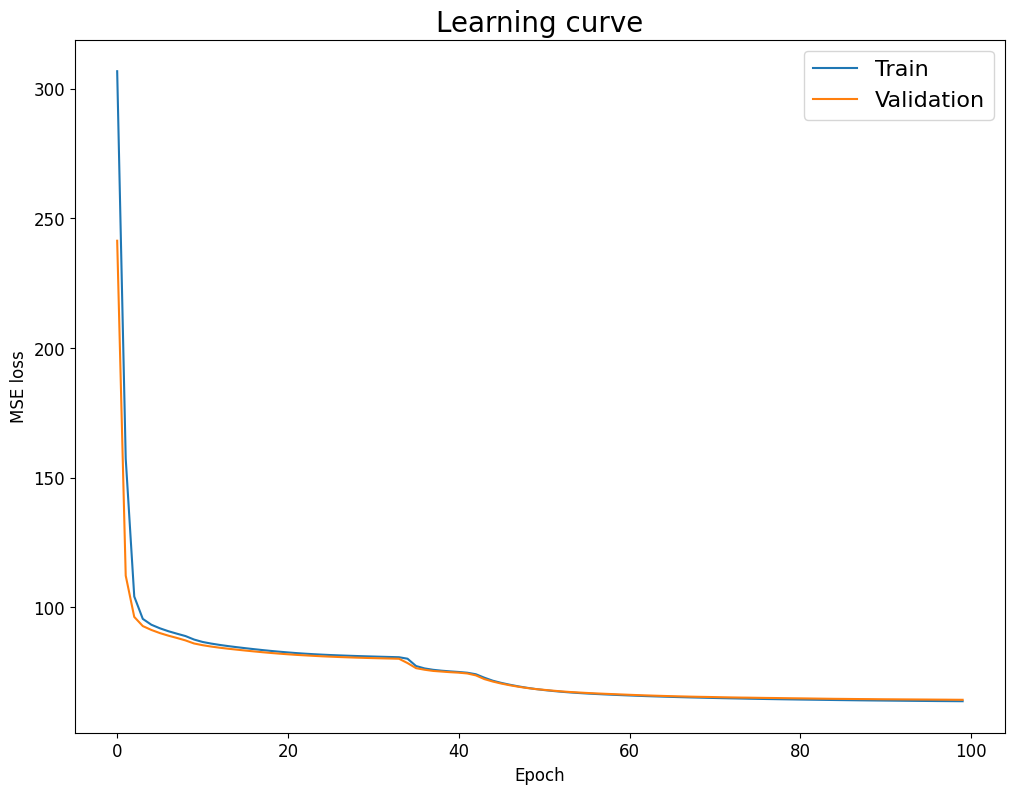

In [10]:
# Plot the learning curves

fig = plt.figure(figsize=(12, 9))

plt.plot(history['training_loss'], label='Train')
plt.plot(history['validation_loss'], label='Validation')
plt.xlabel('Epoch', size=12)
plt.ylabel('MSE loss', size=12)
plt.title('Learning curve')
plt.legend()

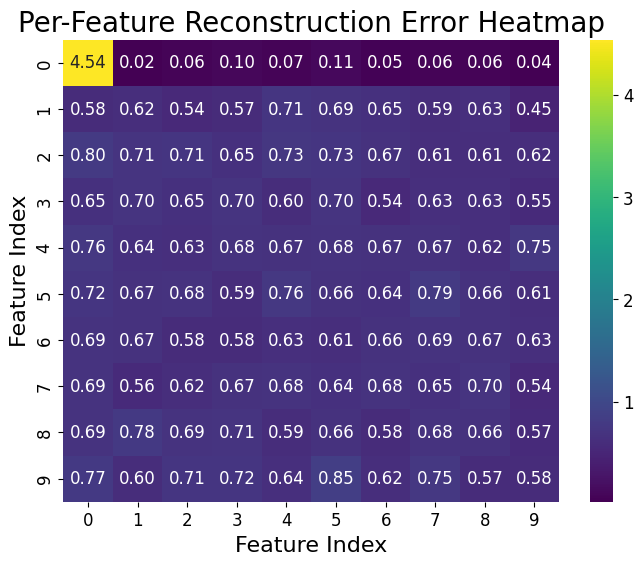

In [11]:
errors = []
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        err = (inputs.flatten(start_dim=1) - outputs.flatten(start_dim=1)) ** 2
        errors.append(err)
errors = np.vstack(errors)
mse = np.mean(errors, axis=0)
mse_matrix = mse.reshape((10, 10))

plt.figure(figsize=(8, 6))
sns.heatmap(mse_matrix, annot=True, fmt=".2f", cmap="viridis")
plt.title("Per-Feature Reconstruction Error Heatmap")
plt.xlabel("Feature Index")
plt.ylabel("Feature Index")
plt.show()

<a name="task-12"></a>

## (1.2) [(index)](#index-task-12)

In [12]:
encoder_model = model[:5]
print(encoder_model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
)


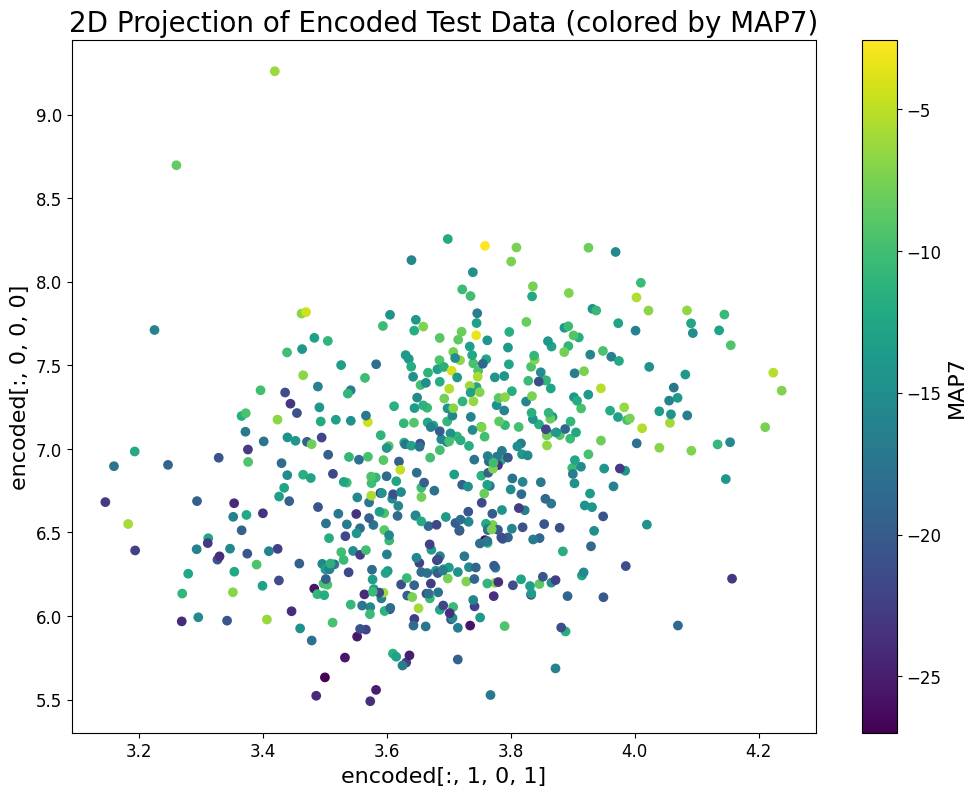

In [13]:
x_list = []
y_list = []

encoder_model.eval()
with torch.no_grad():
    for batch_inputs, labels in test_loader:
        encoded = encoder_model(batch_inputs)

        x_vals = encoded[:, 1, 0, 1].cpu()
        y_vals = encoded[:, 0, 0, 0].cpu()

        x_list.append(x_vals)
        y_list.append(y_vals)

x_coords = torch.cat(x_list, dim=0).numpy()
y_coords = torch.cat(y_list, dim=0).numpy()

plt.figure(figsize=(12, 9))
scatter = plt.scatter(x_coords, y_coords, c=map7_test_tensor, cmap='viridis')
plt.colorbar(scatter, label='MAP7')
plt.xlabel('encoded[:, 1, 0, 1]')
plt.ylabel('encoded[:, 0, 0, 0]')
plt.title('2D Projection of Encoded Test Data (colored by MAP7)')
plt.show()


In [14]:
encoder_model.eval()
encoded_list = []

with torch.no_grad():
    for batch_inputs, labels in train_loader:
        # Get the full encoded output
        encoded = encoder_model(batch_inputs)

        # Append the entire encoded result to the list
        encoded_list.append(encoded)

# Concatenate all the encoded outputs from all batches
encoded_all = torch.cat(encoded_list, dim=0).cpu()  # Concatenate along batch dimension
encoded_trained = encoded_all.view(encoded_all.size(0), -1)

encoded_list = []

with torch.no_grad():
    for batch_inputs, labels in val_loader:
        # Get the full encoded output
        encoded = encoder_model(batch_inputs)

        # Append the entire encoded result to the list
        encoded_list.append(encoded)

# Concatenate all the encoded outputs from all batches
encoded_all = torch.cat(encoded_list, dim=0).cpu()  # Concatenate along batch dimension
encoded_val = encoded_all.view(encoded_all.size(0), -1)

encoded_list = []

with torch.no_grad():
    for batch_inputs, labels in test_loader:
        # Get the full encoded output
        encoded = encoder_model(batch_inputs)

        # Append the entire encoded result to the list
        encoded_list.append(encoded)

# Concatenate all the encoded outputs from all batches
encoded_all = torch.cat(encoded_list, dim=0).cpu()  # Concatenate along batch dimension
encoded_test = encoded_all.view(encoded_all.size(0), -1)

In [15]:
encoded_test.shape

torch.Size([529, 200])

In [16]:
# Creating training and validation datasets
train_map_dataset = TensorDataset(encoded_trained, map7_train_tensor)
val_map_dataset = TensorDataset(encoded_val, map7_val_tensor)
test_map_dataset = TensorDataset(encoded_test, map7_test_tensor)

# Creating corresponding DataLoaders
train_map_loader = DataLoader(train_map_dataset, batch_size=32, shuffle=False)
val_map_loader = DataLoader(val_map_dataset, batch_size=32, shuffle=False)
test_map_loader = DataLoader(test_map_dataset, batch_size=32, shuffle=False)

In [17]:
def get_model_linear():
    """
    CNN model in PyTorch:
    - Layers are Conv1d(+ReLU), MaxPool1d, Flatten and Linear(+Softmax).
    - It features an Adam optimiser and CrossEntropyLoss criterion.

    Parameters:
        x_train (np.ndarray): Training data
        n_filters (int): Number of filters to be used in the convolutional layer
        k (int): Kernel size in the convolutional layer
        pool_size (int): MaxPool1d window size
        stride_pool (int): Stride of the MaxPool1d sliding window
        classes (List): Output classes

    Returns:
        Model, criterion and optimiser.

    """

    model = Sequential(
        Linear(200, 1)
    )

    criterion = torch.nn.MSELoss() ## <-- SOLUTION
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-3) ## <-- SOLUTION

    return model, criterion, optimiser


In [18]:
linear_model, criterion, optimiser = get_model_linear() ## <-- SOLUTION
print(linear_model)

Sequential(
  (0): Linear(in_features=200, out_features=1, bias=True)
)


In [19]:
def compute_mse_loss_reg(original, reconstructed):
    N = original.shape[0]
    error = (original.view(N,-1) - reconstructed.view(N,-1)) ** 2
    total_loss = torch.mean(torch.sum(error, dim=1))
    return total_loss

In [20]:
def training_loop_linear(train_loader, val_loader, max_num_epochs=100, max_patience=5):
    """
    Training loop with early stopping to monitor the validation accuracy.

    Parameters:
        train_loader (torch.utils.data.DataLoader): Training DataLoader
        val_loader (torch.utils.data.DataLoader): Validation DataLoader
        max_num_epochs (int): Maximum number of epochs
        max_patience (int): max_patience attribute of the EarlyStopping class

    Returns:
        Model, criterion and optimiser.

    """

    history = {'training_loss': [], 'validation_loss': [], 'training_accuracy': [], 'validation_accuracy': []}
    early_stopping = EarlyStopping(max_patience=max_patience)

    for epoch in range(max_num_epochs):
        linear_model.train()
        tr_loss = 0.0
        for inputs_train, value in train_map_loader:
            optimiser.zero_grad()
            outputs = linear_model(inputs_train)
            loss = compute_mse_loss_reg(outputs, value)
            loss.backward()
            optimiser.step()
            tr_loss += loss.item() * inputs_train.size(0)
        history['training_loss'].append(tr_loss / len(train_loader.dataset))

        linear_model.eval()
        val_loss = 0.0
        with torch.no_grad():
          for inputs_val, value in val_map_loader:
                outputs_val = linear_model(inputs_val)
                loss_val = compute_mse_loss_reg(value, outputs_val)
                val_loss += loss_val.item() * inputs_val.size(0)
        history['validation_loss'].append(val_loss / len(val_loader.dataset))

        print(f"Epoch {epoch+1}/{max_num_epochs}: Training Loss: {tr_loss / len(train_loader.dataset):.4f}, Validation Loss: {val_loss / len(val_loader.dataset):.4f}")

        # Early stopping check
        early_stopping.step(tr_loss / len(train_loader.dataset))
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

    return history, linear_model

In [21]:
# Calling the training loop
max_num_epochs = 1000
max_patience = 10

history, model = training_loop_linear(train_loader, val_loader, max_num_epochs, max_patience)

Epoch 1/1000: Training Loss: 73.0102, Validation Loss: 26.5244
Epoch 2/1000: Training Loss: 26.0839, Validation Loss: 26.2229
Epoch 3/1000: Training Loss: 25.7597, Validation Loss: 25.9139
Epoch 4/1000: Training Loss: 25.4578, Validation Loss: 25.5543
Epoch 5/1000: Training Loss: 25.1167, Validation Loss: 25.1586
Epoch 6/1000: Training Loss: 24.7449, Validation Loss: 24.7360
Epoch 7/1000: Training Loss: 24.3495, Validation Loss: 24.2932
Epoch 8/1000: Training Loss: 23.9365, Validation Loss: 23.8351
Epoch 9/1000: Training Loss: 23.5104, Validation Loss: 23.3660
Epoch 10/1000: Training Loss: 23.0755, Validation Loss: 22.8893
Epoch 11/1000: Training Loss: 22.6353, Validation Loss: 22.4084
Epoch 12/1000: Training Loss: 22.1927, Validation Loss: 21.9260
Epoch 13/1000: Training Loss: 21.7504, Validation Loss: 21.4447
Epoch 14/1000: Training Loss: 21.3108, Validation Loss: 20.9669
Epoch 15/1000: Training Loss: 20.8756, Validation Loss: 20.4945
Epoch 16/1000: Training Loss: 20.4466, Validation

In [43]:
def r_squared(y_true, y_pred):

    y_true = y_true.cpu().numpy().reshape(y_true.shape[0], -1)
    y_pred = y_pred.detach().cpu().numpy().reshape(y_pred.shape[0], -1)

    ss_total = np.sum((y_true - np.mean(y_true))**2)
    ss_residual = np.sum((y_true - y_pred)**2)

    return 1 - (ss_residual / ss_total)

In [45]:
r_squared(map7_test_tensor, model(encoded_test))

np.float32(0.669798)

<a name="task-2"></a>

# Task 2: Graph-based learning [(index)](#index-task-2)

In [22]:
PATH='/content/drive/MyDrive/data_science_cw2/' # Put your path to the file here

# Dataset upload #
import pandas as pd
dataset = pd.read_csv(PATH + "gene_expression_transcriptomic_data.csv")

X = dataset.iloc[:400, :10].values # extract the first 400 rows and 10 columns
treatment = dataset.iloc[:, 101].values[:400, ] # extract the corresponding 400 treatment labels

<a name="task-21"></a>

## (2.1) [(index)](#index-task-21)

In [47]:
def cosine_similarity(X):
  cos_sim = np.dot(X, X.T) / (np.linalg.norm(X, axis=1)[:, np.newaxis] * np.linalg.norm(X, axis=1))
  return cos_sim

In [55]:
from scipy.sparse.csgraph import connected_components, laplacian
from scipy.linalg import eigh
import networkx as nx
N=400

S = cosine_similarity(X)
delta_values = np.linspace(S.min(), S.max(), 200)
num_components = []
sparsity_levels = []

for delta in delta_values:
    A_delta = np.where(S >= delta, S, 0)
    np.fill_diagonal(A_delta, 0)

    n_delta, _ = connected_components(csgraph=A_delta, directed=False)
    num_components.append(n_delta)

    num_edges = np.count_nonzero(A_delta) / 2
    max_edges = N * (N - 1) / 2
    sparsity = num_edges / max_edges

connected_deltas = [delta for i, delta in enumerate(delta_values) if num_components[i] == 1]
delta_star = max(connected_deltas) if connected_deltas else None

In [56]:
def plot_graph(adjacency, x_coord, y_coord, node_size, node_color):
    """Plot undirected graph.

    Parameters:
        adjacency (np.array): N x N adjacency matrix.
        x_coord (np.array): X-coordinates for N nodes.
        y_coord (np.array): Y-coordinates for N nodes.
        node_size (np.array): Size for each of the N nodes.
        node_color (np.array): Color for each of the N nodes.
    """

    # plot
    fig, ax = plt.subplots(1)

    # plot edges
    for i in range(N):
        for j in range(i+1,N):
            if adjacency[i,j] > 0:
                ax.plot([x_coord[i],x_coord[j]],[y_coord[i],y_coord[j]], color="black", alpha=0.5, linewidth=0.3)

    # plot nodes
    scatter = ax.scatter(x_coord,y_coord,s=0.2*node_size, c=node_color, zorder=10)

    return ax

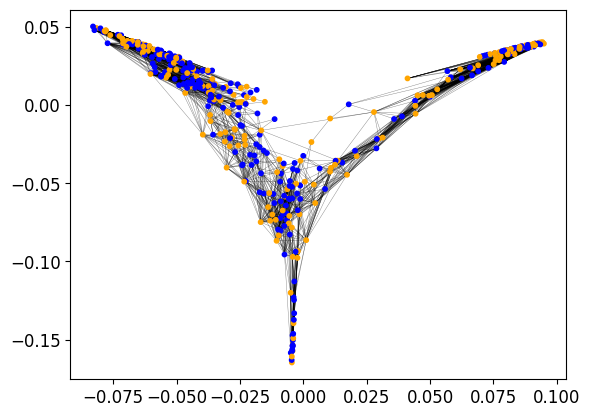

Final Sparsity Level: 0.0544


In [59]:
# Step 5: Find the largest δ* that keeps the graph fully connected
connected_deltas = [delta for i, delta in enumerate(delta_values) if num_components[i] == 1]
delta_star = max(connected_deltas) if connected_deltas else None

# Step 6: Compute final sparse graph G(δ*)
A_final = np.where(S >= delta_star, S, 0)
np.fill_diagonal(A_final, 0)

# Compute final sparsity level
num_edges_final = np.count_nonzero(A_final) / 2
sparsity_final = num_edges_final / max_edges
# Compute normalized Laplacian matrix
L = laplacian(A_final, normed=True)

# Compute eigenvalues and eigenvectors
eigvals, eigvecs = eigh(L)

# Use second and third eigenvectors as node coordinates
xy_pos = eigvecs[:, 1:3]

# Step 7: Generate random treatment labels (1 = Experiment, 0 = Control)
treatment_labels = np.random.choice([0, 1], size=N)

# Assign colors based on treatment labels
node_colors = np.array(['orange' if label == 1 else 'blue' for label in treatment_labels])

# Step 9: Plot the final sparse graph using the defined function
plot_graph(A_final, xy_pos[:, 0], xy_pos[:, 1], np.ones(N) * 50, node_colors)
plt.show()

# Output final sparsity level
print(f"Final Sparsity Level: {sparsity_final:.4f}")



<a name="task-22"></a>

## (2.2) [(index)](#index-task-22)

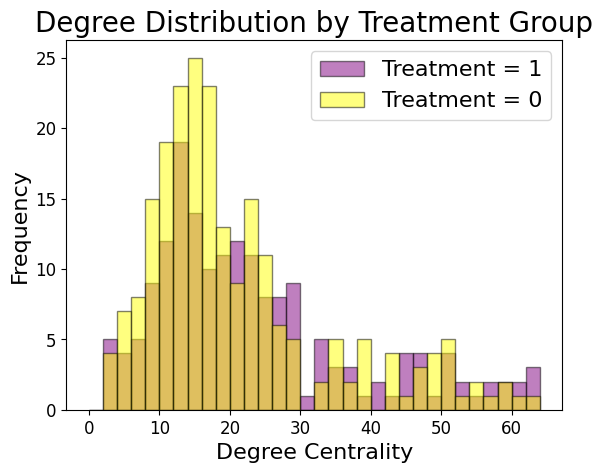

Mean Degree for Treatment = 1: 23.16
Mean Degree for Treatment = 0: 20.52


In [62]:
# Step 10: Compute Degree Centrality
degree_centrality = np.sum(A_final > 0, axis=1)

# Separate degree centralities by treatment label
degree_treatment_1 = degree_centrality[treatment_labels == 1]
degree_treatment_0 = degree_centrality[treatment_labels == 0]

# Compute mean degree for each treatment group
mean_degree_treatment_1 = np.mean(degree_treatment_1)
mean_degree_treatment_0 = np.mean(degree_treatment_0)

# Plot histograms of degree centralities with improved formatting
fig, ax = plt.subplots(1)
bins = np.arange(0, degree_centrality.max() + 2, 2)
ax.hist(degree_treatment_1, bins=bins, alpha=0.5, edgecolor='black', label="Treatment = 1", color="purple")
ax.hist(degree_treatment_0, bins=bins, alpha=0.5, edgecolor='black', label="Treatment = 0", color="yellow")
ax.set(xlabel="Degree Centrality", ylabel="Frequency", title="Degree Distribution by Treatment Group")
ax.legend()
plt.show()

# Output mean degrees
print(f"Mean Degree for Treatment = 1: {mean_degree_treatment_1:.2f}")
print(f"Mean Degree for Treatment = 0: {mean_degree_treatment_0:.2f}")
